# Analyse des gelernten Parametervektors C

Für den Lauf `halvorsen_9params_train_m1_m0p75_m0p5_m100_p10_cphi`.
**Benutzung:** Python-Kernel mit `torch`, `numpy`, `pandas` und `matplotlib` wählen und **Run All** ausführen.
Es wird nichts trainiert. Checkpoint und gespeicherte Trajektorien werden nur gelesen.
Der vollständige Vektor steht direkt im ersten Ergebnisblock.

Die Modellgleichung in `train_halvorsen_plain.py`, Klasse `AL_RNN`, lautet

$$z_{t+1}=A\odot z_t+Wg(z_t)+h+C\phi_t.$$

Nur die letzten $P$ Komponenten von $g$ werden mit ReLU aktiviert. Bei einem skalaren
$\phi$ ist $C$ eine Matrix der Form $(M,1)$, also praktisch ein Vektor.
$C_i=\partial z_{t+1,i}/\partial\phi_t$ **bei festgehaltenem Zustand**.
Die ersten $N$ Zustände sind die beobachteten Koordinaten; `B` dient hier der
Initialisierung des latenten Zustands und ist kein Ausgabedecoder.

Alle Neuronenindizes in diesem Notebook sind **nullbasiert**, passend zu Python.

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

RUN_NAME = "halvorsen_9params_train_m1_m0p75_m0p5_m100_p10_cphi"
# Bei einem anderen Arbeitsverzeichnis hier einen absoluten Pfad eintragen.
RUN_DIR = None

if RUN_DIR is None:
    candidates = [parent / suffix / "runs" / RUN_NAME
                  for parent in (Path.cwd(), *Path.cwd().parents)
                  for suffix in (Path("."), Path("ALRNN-DSR/alrnn_python"))]
    RUN_DIR = next((p for p in candidates if (p / "model.pt").is_file()), None)
    if RUN_DIR is None:
        raise FileNotFoundError("Run nicht gefunden. RUN_DIR oben als absoluten Pfad setzen.")
RUN_DIR = Path(RUN_DIR).resolve()

with (RUN_DIR / "metrics.json").open(encoding="utf-8-sig") as stream:
    metrics = json.load(stream)
args = metrics["args"]
state = torch.load(RUN_DIR / "model.pt", map_location="cpu", weights_only=True)
if "C" not in state or state["C"].ndim != 2 or state["C"].shape[1] != 1:
    raise ValueError("Dieses Notebook erwartet einen Checkpoint mit skalarem phi und C.shape=(M,1).")
arrays = {key: value.detach().cpu().numpy().astype(np.float64)
          for key, value in state.items()}
c = arrays["C"][:, 0]
h = arrays["h"]
M, N, P = len(c), arrays["B"].shape[0], int(args["pwl_units"])
if not (0 <= P <= M and N <= M and arrays["W"].shape == (M, M)
        and h.shape == (M,) and arrays["A"].shape == (M,)):
    raise ValueError("Inkonsistente Modelldimensionen.")
if not all(np.isfinite(a).all() for a in arrays.values()):
    raise ValueError("Checkpoint enthält nichtendliche Werte.")
train_phi = np.asarray(args["train_phi_values"], dtype=float)
phi_ref = float(train_phi.mean())
phi_span = float(np.ptp(train_phi))
energy = c ** 2
total_energy = float(energy.sum())
energy_share = energy / total_energy if total_energy else np.zeros_like(c)
order = np.argsort(-np.abs(c), kind="stable")
index = np.arange(M)
observed = index < N
relu = index >= M - P
groups = np.where(observed, "Beobachtete Koordinaten",
                  np.where(relu, "Latent, ReLU", "Latent, linear"))
colors_by_group = {"Beobachtete Koordinaten": "#20817b",
                   "Latent, linear": "#6485ba", "Latent, ReLU": "#d87a32"}
colors = [colors_by_group[g] for g in groups]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10})

print("Run:", RUN_DIR)
print("SHA256 model.pt:", hashlib.sha256((RUN_DIR / "model.pt").read_bytes()).hexdigest())
print(f"C.shape = {state['C'].shape}; M={M}, N={N}, P={P}")
print("Trainings-phi:", train_phi)
print("Python:", sys.version.split()[0], "| Torch:", torch.__version__)
print("\nVollständiger C-Vektor (Eintrag an Position i entspricht C[i]):")
with np.printoptions(threshold=np.inf, precision=9, linewidth=110):
    print(c)

Run: C:\Users\koray\OneDrive\Dokumente\Studium\Master\Heidelberg\Master_Thesis\ALRNN-DSR\alrnn_python\runs\halvorsen_9params_train_m1_m0p75_m0p5_m100_p10_cphi
SHA256 model.pt: 823b8700eac50e8d40c15a28c994930668a821e695e7457e480654aa69e13191
C.shape = torch.Size([200, 1]); M=200, N=3, P=20
Trainings-phi: [-1.   -0.75 -0.5 ]
Python: 3.14.0 | Torch: 2.11.0+cpu

Vollständiger C-Vektor (Eintrag an Position i entspricht C[i]):
[-1.682614535e-02 -9.570582770e-03 -1.580192707e-02 -1.028031297e-02  3.685862757e-03 -4.765737802e-03
 -6.042103632e-04  3.036452690e-04  5.364520475e-04 -5.550116301e-03 -1.072655339e-02 -3.455232130e-03
  8.972248179e-04  1.488779765e-02 -2.899085870e-03 -5.866809282e-03 -1.691479702e-04  2.276654122e-03
  6.392392796e-03 -7.243639790e-03 -1.158059947e-02  1.131708175e-02 -9.575212607e-04  5.637527909e-03
  1.111629512e-02 -7.977194153e-03 -6.214908790e-03 -1.211465453e-03  1.698572934e-02  2.418787626e-04
  9.785489179e-03  2.500830684e-03  1.558805932e-03  1.94549

## 1. Einzelwerte und erste Kennzahlen

`Energieanteil` bezeichnet hier ausschließlich den Anteil $C_i^2/\sum_j C_j^2$
an der quadrierten Vektornorm. Das ist **kein Anteil an erklärter Varianz**.
Die Schwellen unten sind beschreibende Größen relativ zum größten Betrag;
kleine Werte werden dadurch nicht automatisch dynamisch unwichtig.

In [2]:
table = pd.DataFrame({
    "Index": index, "Gruppe": groups, "beobachtet": observed, "ReLU": relu,
    "C_i": c, "Betrag": np.abs(c), "Energieanteil": energy_share,
    "h_i": h, "Delta_Bias_Trainingsspanne": c * phi_span,
})
summary = pd.Series({
    "Anzahl": M, "Minimum": c.min(), "Maximum": c.max(),
    "Mittelwert": c.mean(), "Median": np.median(c),
    "Standardabweichung (Population)": c.std(), "L1-Norm": np.abs(c).sum(),
    "L2-Norm": np.linalg.norm(c), "Positive Einträge": int((c > 0).sum()),
    "Negative Einträge": int((c < 0).sum()), "Exakt null": int((c == 0).sum()),
    "Betrag < 1% des Maximums": int((np.abs(c) < 0.01 * np.abs(c).max()).sum()),
    "Betrag < 10% des Maximums": int((np.abs(c) < 0.1 * np.abs(c).max()).sum()),
}, name="Wert")
display(summary.to_frame())
print("Alle Einträge, ohne Tabellenkürzung:")
with pd.option_context("display.max_rows", M, "display.float_format", "{:.8g}".format):
    display(table)
print("Größte 15 Beträge:")
display(table.iloc[order[:15]])

,Wert
Anzahl,200.000000
Minimum,-0.053247
Maximum,0.021706
Mittelwert,-0.002532
Median,-0.000628
Standardabweichung (Population),0.011348
L1-Norm,1.585292
L2-Norm,0.164434
Positive Einträge,91.000000
Negative Einträge,109.000000


Alle Einträge, ohne Tabellenkürzung:


,Index,Gruppe,beobachtet,ReLU,C_i,Betrag,Energieanteil,h_i,Delta_Bias_Trainingsspanne
0,0,Beobachtete Koordinaten,True,False,-0.016826145,0.016826145,0.010470891,0.054900132,-0.0084130727
1,1,Beobachtete Koordinaten,True,False,-0.0095705828,0.0095705828,0.0033875922,0.046338461,-0.0047852914
2,2,Beobachtete Koordinaten,True,False,-0.015801927,0.015801927,0.0092349481,0.049217537,-0.0079009635
3,3,"Latent, linear",False,False,-0.010280313,0.010280313,0.0039086522,-0.027465656,-0.0051401565
4,4,"Latent, linear",False,False,0.0036858628,0.0036858628,0.0005024498,0.023931837,0.0018429314
5,5,"Latent, linear",False,False,-0.0047657378,0.0047657378,0.00083999102,0.023500701,-0.0023828689
6,6,"Latent, linear",False,False,-0.00060421036,0.00060421036,1.350177e-05,-0.014416628,-0.00030210518
7,7,"Latent, linear",False,False,0.00030364527,0.00030364527,3.4099451e-06,0.076954611,0.00015182263
8,8,"Latent, linear",False,False,0.00053645205,0.00053645205,1.0643297e-05,0.044741161,0.00026822602
9,9,"Latent, linear",False,False,-0.0055501163,0.0055501163,0.0011392486,-0.016167739,-0.0027750582


Größte 15 Beträge:


,Index,Gruppe,beobachtet,ReLU,C_i,Betrag,Energieanteil,h_i,Delta_Bias_Trainingsspanne
184,184,"Latent, ReLU",False,True,-0.053247,0.053247,0.104860,0.044539,-0.026624
185,185,"Latent, ReLU",False,True,-0.044998,0.044998,0.074885,0.090132,-0.022499
187,187,"Latent, ReLU",False,True,-0.044248,0.044248,0.072411,0.062267,-0.022124
180,180,"Latent, ReLU",False,True,-0.040730,0.040730,0.061353,0.032247,-0.020365
181,181,"Latent, ReLU",False,True,-0.039172,0.039172,0.056750,0.062273,-0.019586
192,192,"Latent, ReLU",False,True,-0.034579,0.034579,0.044222,0.073500,-0.017290
79,79,"Latent, linear",False,False,-0.033512,0.033512,0.041534,-0.100522,-0.016756
189,189,"Latent, ReLU",False,True,-0.033346,0.033346,0.041124,0.053429,-0.016673
182,182,"Latent, ReLU",False,True,0.021706,0.021706,0.017425,-0.055028,0.010853
195,195,"Latent, ReLU",False,True,-0.021546,0.021546,0.017169,0.072108,-0.010773


## 2. Vorzeichen, Verteilung und Konzentration

Die Reihenfolge der Neuronen ist überwiegend frei wählbar. Ein glatter Verlauf,
periodisches Muster oder benachbarte Spitzen wären ohne weitere Strukturannahmen
kein belastbarer Befund. Sinnvoll sind hier die vom Modell vorgegebenen Gruppen:
erste $N$ beobachtete Zustände und letzte $P$ ReLU-Einheiten.

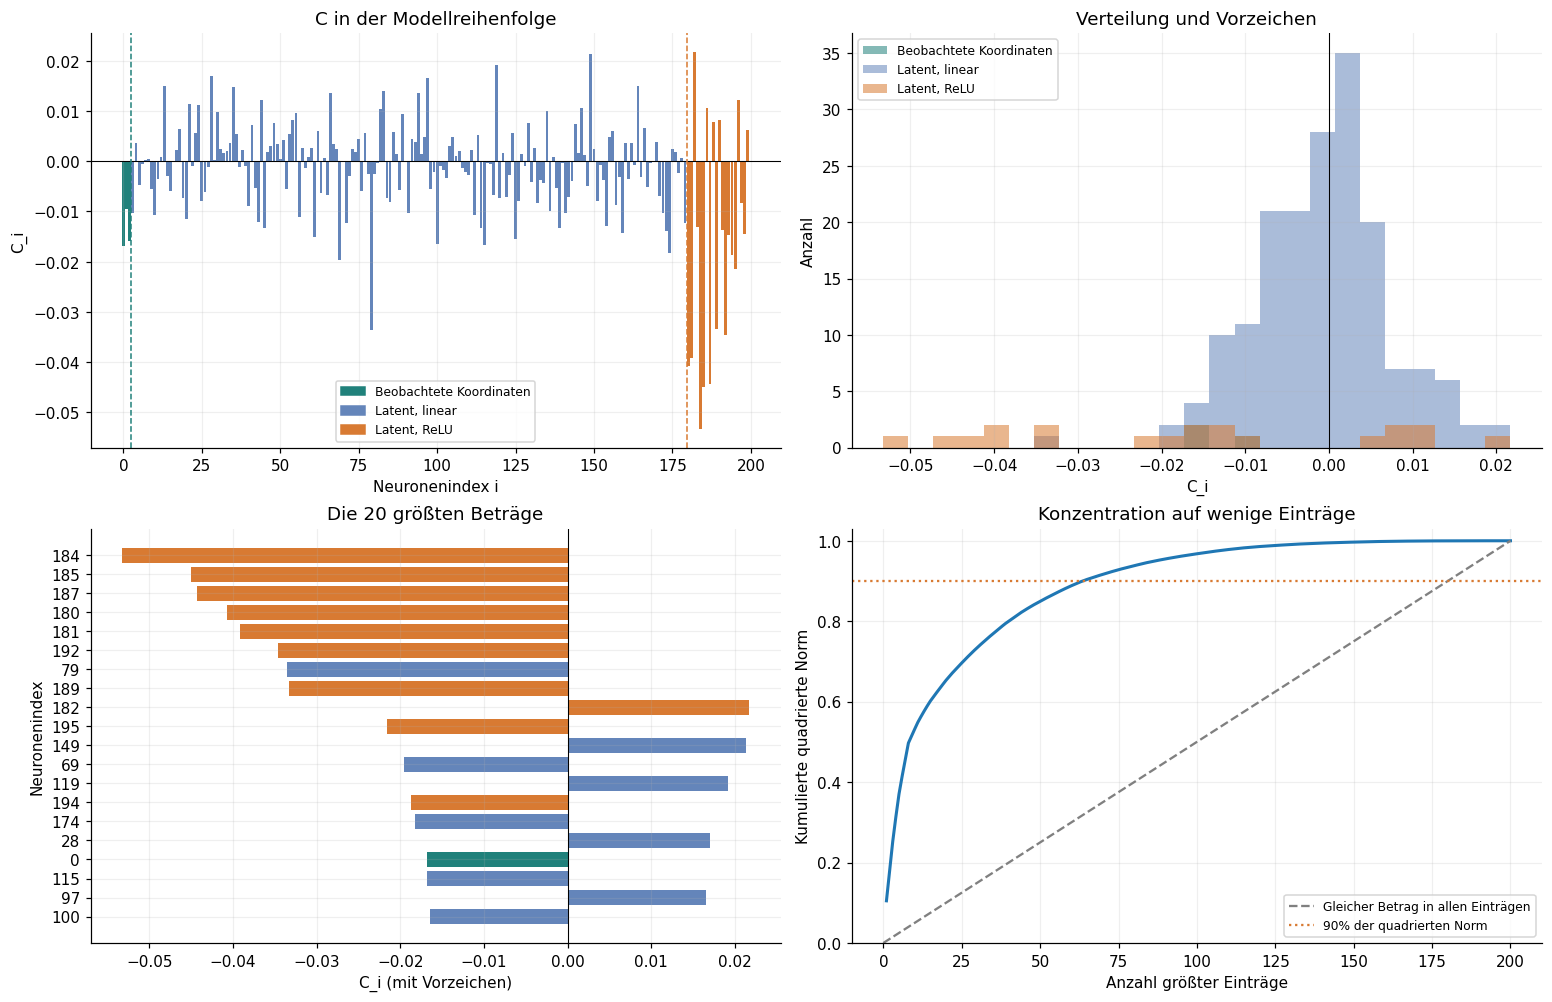

50% der quadrierten Norm liegen in 9/200 Einträgen.
90% der quadrierten Norm liegen in 64/200 Einträgen.
95% der quadrierten Norm liegen in 87/200 Einträgen.
Effektive Anzahl nach inverser Partizipation: 26.31 von 200


In [3]:
from matplotlib.patches import Patch

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)
ax = axes[0, 0]
ax.bar(index, c, color=colors, width=0.9)
ax.axhline(0, color="black", lw=0.7)
ax.axvline(N - 0.5, color="#20817b", ls="--", lw=1)
if P:
    ax.axvline(M - P - 0.5, color="#d87a32", ls="--", lw=1)
ax.set(title="C in der Modellreihenfolge", xlabel="Neuronenindex i", ylabel="C_i")
ax.legend(handles=[Patch(color=col, label=group) for group, col in colors_by_group.items()],
          fontsize=8)

ax = axes[0, 1]
for group, color in colors_by_group.items():
    values = c[groups == group]
    if values.size:
        ax.hist(values, bins=np.histogram_bin_edges(c, bins=25), alpha=0.55,
                color=color, label=group)
ax.axvline(0, color="black", lw=0.7)
ax.set(title="Verteilung und Vorzeichen", xlabel="C_i", ylabel="Anzahl")
ax.legend(fontsize=8)

ax = axes[1, 0]
k = min(20, M)
top = order[:k][::-1]
ax.barh(np.arange(k), c[top], color=[colors[i] for i in top])
ax.set_yticks(np.arange(k), [str(i) for i in top])
ax.axvline(0, color="black", lw=0.7)
ax.set(title=f"Die {k} größten Beträge", xlabel="C_i (mit Vorzeichen)", ylabel="Neuronenindex")

ax = axes[1, 1]
cumulative = np.cumsum(energy_share[order])
ax.plot(np.arange(1, M + 1), cumulative, lw=2)
ax.plot([0, M], [0, 1], "--", color="gray", label="Gleicher Betrag in allen Einträgen")
ax.axhline(0.9, color="#d87a32", ls=":", label="90% der quadrierten Norm")
ax.set(title="Konzentration auf wenige Einträge", xlabel="Anzahl größter Einträge",
       ylabel="Kumulierte quadrierte Norm", ylim=(0, 1.03))
ax.legend(fontsize=8)
plt.show()

if total_energy:
    for target in (0.5, 0.9, 0.95):
        count = int(np.searchsorted(cumulative, target) + 1)
        print(f"{target:.0%} der quadrierten Norm liegen in {count}/{M} Einträgen.")
    effective_count = 1 / np.sum(energy_share ** 2)
    print(f"Effektive Anzahl nach inverser Partizipation: {effective_count:.2f} von {M}")
else:
    print("C ist der Nullvektor; Konzentrationsmaße sind nicht definiert.")

## 3. Welche Zustandsgruppen werden direkt angesprochen?

Neben dem gesamten Normanteil vergleichen wir den RMS-Wert
$\sqrt{\mathrm{mean}(C_i^2)}$ pro Gruppe. So berücksichtigt der Vergleich,
dass die Gruppen unterschiedlich viele Einträge haben.
`Faktor ggü. gleichem Betrag` ist Normanteil geteilt durch Anteil der Neuronen:
ein Wert über 1 bedeutet überdurchschnittliche Kopplungsstärke pro Eintrag.
Dies ist ein deskriptiver Vergleich, kein Signifikanztest.

,Anzahl,Mittelwert C,Mittlerer Betrag,RMS C,Normanteil,Faktor ggü. gleichem Betrag
Gruppe,,,,,,
Beobachtete Koordinaten,3,-0.014066,0.014066,0.014427,0.023093,1.539562
"Latent, linear",177,-0.000769,0.006110,0.008071,0.426452,0.481867
"Latent, ReLU",20,-0.016402,0.023078,0.027280,0.550454,5.504543


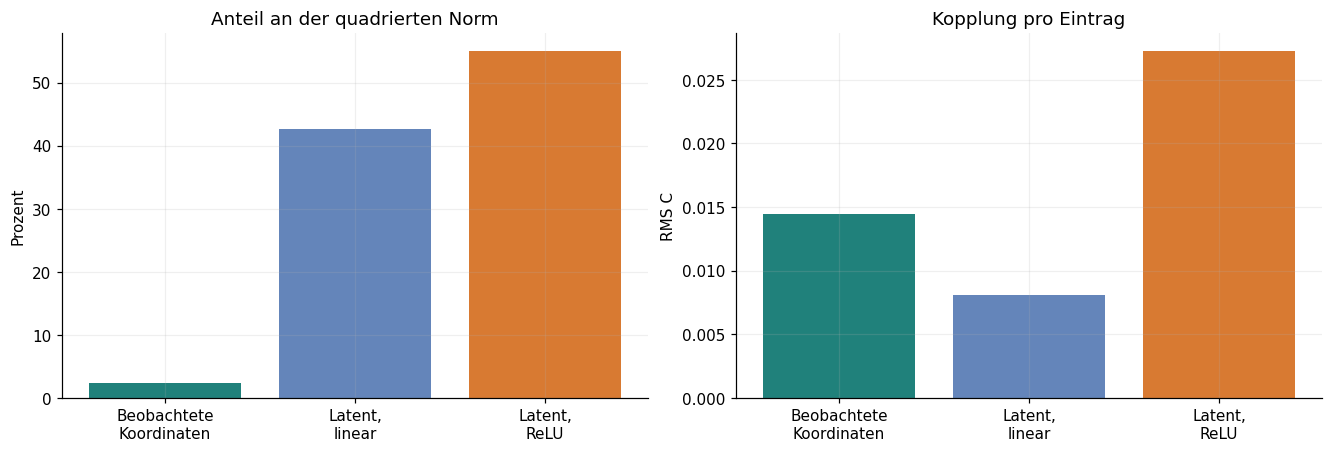

Direkter Einfluss auf die beobachteten Koordinaten:


,Index,C_i,Delta_Bias_Trainingsspanne
0,0,-0.016826,-0.008413
1,1,-0.009571,-0.004785
2,2,-0.015802,-0.007901


In [4]:
group_rows = []
for group in colors_by_group:
    mask = groups == group
    if not mask.any():
        continue
    share = energy_share[mask].sum()
    group_rows.append({"Gruppe": group, "Anzahl": int(mask.sum()),
                       "Mittelwert C": c[mask].mean(),
                       "Mittlerer Betrag": np.abs(c[mask]).mean(),
                       "RMS C": np.sqrt(np.mean(c[mask] ** 2)),
                       "Normanteil": share,
                       "Faktor ggü. gleichem Betrag": share / mask.mean()})
group_table = pd.DataFrame(group_rows).set_index("Gruppe")
display(group_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
group_colors = [colors_by_group[g] for g in group_table.index]
labels = [g.replace(" ", "\n", 1) for g in group_table.index]
axes[0].bar(labels, group_table["Normanteil"] * 100, color=group_colors)
axes[0].set(title="Anteil an der quadrierten Norm", ylabel="Prozent")
axes[1].bar(labels, group_table["RMS C"], color=group_colors)
axes[1].set(title="Kopplung pro Eintrag", ylabel="RMS C")
plt.show()
print("Direkter Einfluss auf die beobachteten Koordinaten:")
display(table.loc[observed, ["Index", "C_i", "Delta_Bias_Trainingsspanne"]])

## 4. Was bedeutet C für verschiedene phi-Werte?

Für konstantes $\phi$ wirkt die Kopplung als effektiver Bias $h_\mathrm{eff}=h+C\phi$.
Beim Vergleich zweier Parameterwerte gilt exakt $\Delta h_\mathrm{eff}=C\Delta\phi$.
Die Heatmap zeigt diesen Bias für die größten Kopplungen. Außerhalb des markierten
Trainingsbereichs handelt es sich um Extrapolation des Eingangs.

Da die Trainingswerte hier nicht um null liegen, betrachten wir zusätzlich den
Bias am mittleren Trainingswert $h_\mathrm{ref}=h+C\bar\phi$.
Dieselbe Gleichung lässt sich dann als $h_\mathrm{ref}+C(\phi-\bar\phi)$ schreiben.
Ein Vergleich von $C_i$ nur mit $h_i$ kann vom gewählten Nullpunkt von $\phi$ abhängen;
bei $h_i\approx0$ wäre auch ein Quotient instabil. Deshalb zeigen wir keinen solchen Quotienten.

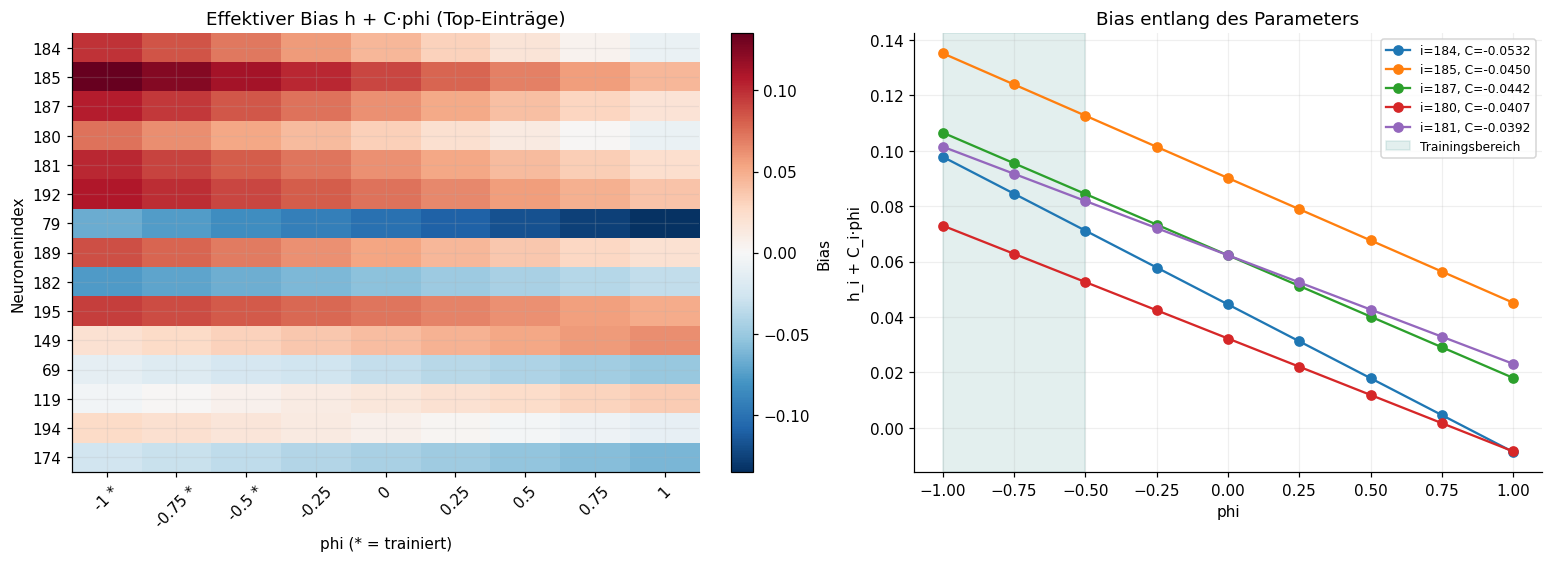

Mittlerer Trainingswert: -0.75; Trainingsspanne Δphi=0.5
||C·Δphi||₂ über die Trainingsspanne: 0.0822172
||h||₂=0.645125; ||h_ref||₂=0.65958


,Index,C_i,h_i,h_ref_i,Delta_Bias_Trainingsspanne
0,184,-0.053247,0.044539,0.084474,-0.026624
1,185,-0.044998,0.090132,0.123881,-0.022499
2,187,-0.044248,0.062267,0.095454,-0.022124
3,180,-0.040730,0.032247,0.062794,-0.020365
4,181,-0.039172,0.062273,0.091652,-0.019586
5,192,-0.034579,0.073500,0.099434,-0.017290
6,79,-0.033512,-0.100522,-0.075388,-0.016756
7,189,-0.033346,0.053429,0.078438,-0.016673
8,182,0.021706,-0.055028,-0.071308,0.010853
9,195,-0.021546,0.072108,0.088267,-0.010773


In [5]:
phi_grid = np.unique(np.r_[np.linspace(-1, 1, 9), train_phi])
h_ref = h + c * phi_ref
effective_bias = h[:, None] + c[:, None] * phi_grid[None, :]
top = order[:min(15, M)]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
bound = max(float(np.max(np.abs(effective_bias[top]))), np.finfo(float).eps)
im = axes[0].imshow(effective_bias[top], cmap="RdBu_r", vmin=-bound, vmax=bound, aspect="auto")
axes[0].set_yticks(np.arange(len(top)), [str(i) for i in top])
axes[0].set_xticks(np.arange(len(phi_grid)),
                   [f"{v:g}" + (" *" if np.isclose(v, train_phi).any() else "") for v in phi_grid],
                   rotation=45)
axes[0].set(title="Effektiver Bias h + C·phi (Top-Einträge)", xlabel="phi (* = trainiert)",
            ylabel="Neuronenindex")
fig.colorbar(im, ax=axes[0], label="Bias")
for i in top[:5]:
    axes[1].plot(phi_grid, effective_bias[i], marker="o", label=f"i={i}, C={c[i]:.4f}")
axes[1].axvspan(train_phi.min(), train_phi.max(), alpha=0.12, color="#20817b",
               label="Trainingsbereich")
axes[1].set(title="Bias entlang des Parameters", xlabel="phi", ylabel="h_i + C_i·phi")
axes[1].legend(fontsize=8)
plt.show()
print(f"Mittlerer Trainingswert: {phi_ref:g}; Trainingsspanne Δphi={phi_span:g}")
print(f"||C·Δphi||₂ über die Trainingsspanne: {np.linalg.norm(c * phi_span):.6g}")
print(f"||h||₂={np.linalg.norm(h):.6g}; ||h_ref||₂={np.linalg.norm(h_ref):.6g}")
display(pd.DataFrame({"Index": top, "C_i": c[top], "h_i": h[top],
                      "h_ref_i": h_ref[top], "Delta_Bias_Trainingsspanne": c[top] * phi_span}))

## 5. Optional: Kopplung relativ zur Skala gespeicherter Zustände

Die gespeicherten `*_orbit.npy` enthalten freie Modelltrajektorien mit allen latenten
Koordinaten. Der Trainingscode hat den Transienten vor dem Speichern bereits entfernt;
standardmäßig werden deshalb alle gespeicherten Schritte verwendet.
Wir vergleichen $|C_i|\Delta\phi$ mit der empirischen Standardabweichung von $z_i$.
Dieser dimensionslose Quotient hilft beim Vergleich unterschiedlich skalierter
latenter Koordinaten. Er ist **keine vorhergesagte Zustandsänderung** und kein
kausales Wichtigkeitsmaß: Rückkopplung und Aktivierungswechsel fehlen darin.
Wir zeigen Training und nicht trainierte Parameter getrennt an.

Für ReLU-Einheiten ergänzt der aktive Anteil $\Pr(z_i>0)$, ob sie auf diesen
Trajektorien meist aktiv, inaktiv oder wechselnd sind. Das allein beweist
keine durch $\phi$ verursachten Schaltvorgänge.

,,Median_Skalenquotient,Konstante_Einheiten,Mittlerer_ReLU_Aktivanteil
phi,trainiert,,,
-1.00,True,0.046777,0,0.588720
-0.75,True,0.047893,0,0.574585
-0.50,True,0.047157,0,0.583010
-0.25,False,0.046801,0,0.576885
0.00,False,0.046265,0,0.576665
0.25,False,0.046068,0,0.575180
0.50,False,0.045847,0,0.570985
0.75,False,0.045227,0,0.572160
1.00,False,0.052085,0,0.580970


Größte Kopplungen nach Skalennormierung (Median über Trainingsorbits):


,Index,Gruppe,C_i,Median_Skalenquotient,Mittlerer_ReLU_Aktivanteil
149,149,"Latent, linear",0.021318,0.558618,NaN
94,94,"Latent, linear",0.013525,0.443218,NaN
119,119,"Latent, linear",0.019143,0.437872,NaN
71,71,"Latent, linear",-0.012225,0.434179,NaN
45,45,"Latent, linear",-0.013236,0.404751,NaN
79,79,"Latent, linear",-0.033512,0.395496,NaN
69,69,"Latent, linear",-0.019573,0.382981,NaN
139,139,"Latent, linear",-0.013320,0.324793,NaN
83,83,"Latent, linear",0.014013,0.305189,NaN
125,125,"Latent, linear",-0.015464,0.294300,NaN


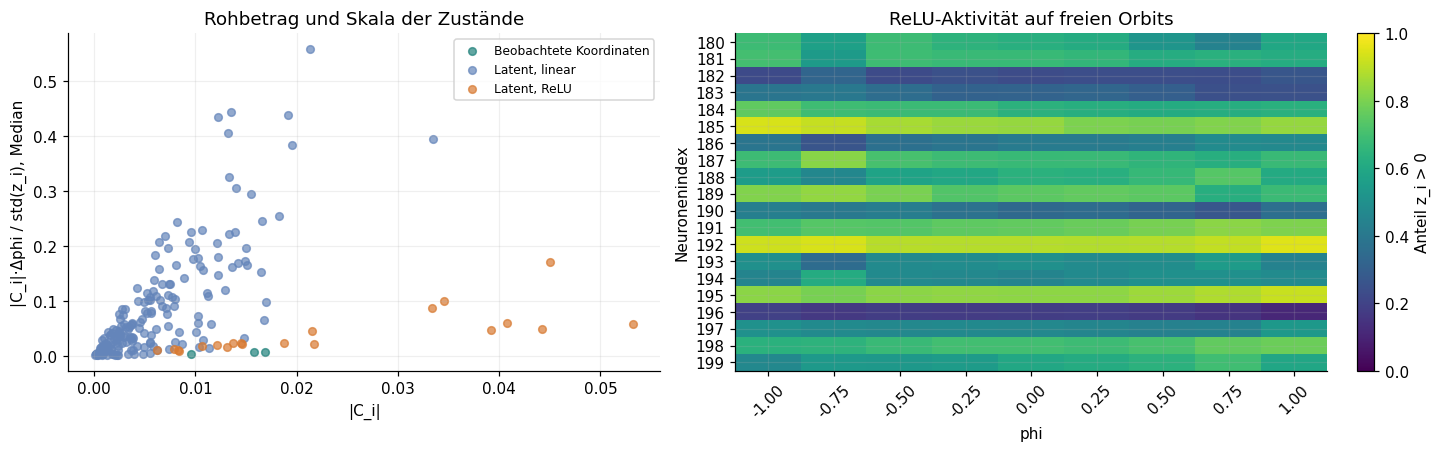

In [6]:
ANALYZE_ORBITS = True  # Für eine reine Checkpointanalyse auf False setzen.
DISCARD = 0  # Der Trainingscode hat t_transient vor dem Speichern schon entfernt.

def phi_from_stem(stem):
    token = stem.split("_traj_", 1)[0].removeprefix("phi_")
    return float(token.replace("m", "-").replace("p", "."))

orbit_rows = []
if ANALYZE_ORBITS:
    for path in sorted(RUN_DIR.glob("*_orbit.npy")):
        phi = phi_from_stem(path.stem.removesuffix("_orbit"))
        orbit = np.load(path, mmap_mode="r", allow_pickle=False)
        if orbit.ndim != 2 or orbit.shape[1] != M or len(orbit) <= DISCARD + 1:
            print(f"Übersprungen (Form/Länge): {path.name}, {orbit.shape}")
            continue
        z = np.asarray(orbit[DISCARD:], dtype=np.float64)
        if not np.isfinite(z).all():
            print(f"Übersprungen (nichtendliche Werte): {path.name}")
            continue
        std = z.std(axis=0)
        valid = std > 1e-12  # Konstante Einheiten nicht durch Division aufblasen.
        scaled = np.full(M, np.nan)
        np.divide(np.abs(c) * phi_span, std, out=scaled, where=valid)
        orbit_rows.append(pd.DataFrame({
            "phi": phi, "trainiert": bool(np.isclose(phi, train_phi, atol=1e-5).any()),
            "Index": index, "Gruppe": groups, "Std_z": std,
            "Bias_Spanne_pro_Std_z": scaled,
            "ReLU_aktiv": np.where(relu, (z > 0).mean(axis=0), np.nan),
        }))
        del z, orbit

if orbit_rows:
    orbit_table = pd.concat(orbit_rows, ignore_index=True)
    display(orbit_table.groupby(["phi", "trainiert"], sort=True).agg(
        Median_Skalenquotient=("Bias_Spanne_pro_Std_z", "median"),
        Konstante_Einheiten=("Std_z", lambda x: int((x <= 1e-12).sum())),
        Mittlerer_ReLU_Aktivanteil=("ReLU_aktiv", "mean")))
    reference_rows = orbit_table[orbit_table["trainiert"]]
    if reference_rows.empty:
        reference_rows = orbit_table
        print("Keine Trainingsorbits erkannt: Übersicht verwendet alle gespeicherten Orbits.")
    per_neuron = reference_rows.groupby("Index").agg(
        Median_Skalenquotient=("Bias_Spanne_pro_Std_z", "median"),
        Mittlerer_ReLU_Aktivanteil=("ReLU_aktiv", "mean"))
    ranked = table.join(per_neuron, on="Index").sort_values("Median_Skalenquotient", ascending=False)
    print("Größte Kopplungen nach Skalennormierung (Median über Trainingsorbits):")
    display(ranked[["Index", "Gruppe", "C_i", "Median_Skalenquotient",
                    "Mittlerer_ReLU_Aktivanteil"]].head(15))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
    scatter_data = table.join(per_neuron, on="Index")
    for group, color in colors_by_group.items():
        subset = scatter_data[scatter_data["Gruppe"] == group]
        axes[0].scatter(subset["Betrag"], subset["Median_Skalenquotient"],
                        s=25, alpha=0.7, color=color, label=group)
    axes[0].set(xlabel="|C_i|", ylabel="|C_i|·Δphi / std(z_i), Median",
                title="Rohbetrag und Skala der Zustände")
    axes[0].legend(fontsize=8)
    if P:
        active = orbit_table[orbit_table["Index"] >= M - P].pivot(
            index="Index", columns="phi", values="ReLU_aktiv").sort_index(axis=1)
        im = axes[1].imshow(active, vmin=0, vmax=1, cmap="viridis", aspect="auto")
        axes[1].set_xticks(np.arange(len(active.columns)), [f"{p:.2f}" for p in active.columns], rotation=45)
        axes[1].set_yticks(np.arange(len(active.index)), active.index)
        axes[1].set(title="ReLU-Aktivität auf freien Orbits", xlabel="phi", ylabel="Neuronenindex")
        fig.colorbar(im, ax=axes[1], label="Anteil z_i > 0")
    else:
        axes[1].set_visible(False)
    plt.show()
else:
    print("Orbitanalyse deaktiviert oder keine geeigneten gespeicherten Orbits gefunden.")

## 6. Automatische Kurzbeschreibung

Die folgenden Zahlen werden aus dem geladenen Checkpoint berechnet.
Sie beschreiben diesen Lauf; für Aussagen über die Reproduzierbarkeit wären weitere Seeds nötig.

In [7]:
print(f"C hat {M} Einträge; {int((c > 0).sum())} sind positiv und {int((c < 0).sum())} negativ.")
print(f"Wertebereich [{c.min():.6f}, {c.max():.6f}], L2-Norm {np.linalg.norm(c):.6f}.")
if total_energy:
    k = min(10, M)
    print(f"Die größten {k} Beträge tragen {energy_share[order[:k]].sum():.1%} der quadrierten Norm.")
    if P:
        relu_share = energy_share[relu].sum()
        print(f"Die letzten {P} ReLU-Einheiten ({P/M:.0%} der Einträge) tragen {relu_share:.1%} der quadrierten Norm.")
        print(f"Das entspricht dem Faktor {relu_share/(P/M):.2f} gegenüber gleichem Betrag pro Eintrag.")
    print(f"Die ersten {N} beobachteten Koordinaten tragen {energy_share[observed].sum():.1%} der quadrierten Norm.")
    print(f"Stärkste direkte Kopplung: Index {order[0]}, C_i={c[order[0]]:.6f}.")

C hat 200 Einträge; 91 sind positiv und 109 negativ.
Wertebereich [-0.053247, 0.021706], L2-Norm 0.164434.
Die größten 10 Beträge tragen 53.2% der quadrierten Norm.
Die letzten 20 ReLU-Einheiten (10% der Einträge) tragen 55.0% der quadrierten Norm.
Das entspricht dem Faktor 5.50 gegenüber gleichem Betrag pro Eintrag.
Die ersten 3 beobachteten Koordinaten tragen 2.3% der quadrierten Norm.
Stärkste direkte Kopplung: Index 184, C_i=-0.053247.


### Worauf ich bei der Interpretation achten würde

- **Konzentration:** Wird der Eingang über viele Einheiten verteilt oder hauptsächlich über wenige?
- **ReLU-Gruppe:** Eine starke Kopplung an diese Einheiten kann für Aktivierungswechsel relevant sein.
  Ob sie tatsächlich Schaltschwellen überschreiten, hängt aber vom Zustand und von der Rückkopplung ab.
- **Vorzeichen:** Bei negativem $\phi$ kehrt sich das Vorzeichen des Beitrags $C_i\phi$ um.
  Ein positives $C_i$ bedeutet eine positive *direkte Änderung* bei wachsendem $\phi$.
- **Skalierung:** Die Beträge hängen von der Skalierung des Eingangs und der latenten Koordinaten ab.
  Eine andere Normierung von $\phi$ würde auch $C$ verändern.
- **Langfristiger Einfluss:** Für eine über die gesamte Trajektorie veränderte konstante Eingabe gilt
  außerhalb der ReLU-Knickstellen $s_{t+1}=J_t s_t+C$ mit
  $J_t=\mathrm{diag}(A)+W D_t$. $D_t$ hat Einsen für lineare Einheiten und die
  Aktivierungsindikatoren für ReLU-Einheiten. Große oder kleine $C_i$ erlauben daher
  allein keine Rangfolge der dynamischen Wichtigkeit. Auch $C_i=0$ schließt indirekten Einfluss nicht aus.
- **Keine räumliche Ordnung:** Innerhalb gleichartiger latenter Einheiten ist die Indexreihenfolge
  nicht physikalisch vorgegeben. Keine Frequenzanalyse oder Clusterinterpretation allein aus dieser Reihenfolge ableiten.
- **Generalisierung:** Ein Muster in $C$ belegt keine gute Extrapolation. Dafür die freien Trajektorien
  und die vorhandenen Gütemaße pro $\phi$ separat betrachten.

Ein sinnvoller nächster Schritt wäre, bei identischem Startzustand gezielt $\phi$ zu variieren und
kurze Rollouts oder Aktivierungswechsel zu vergleichen. Bei chaotischer Dynamik sind langfristige
punktweise Trajektorienabstände für sich genommen schwer zu interpretieren.

In [8]:
# Optionaler Export. Erst bei True werden neue Dateien geschrieben.
EXPORT = False
if EXPORT:
    output_dir = RUN_DIR / "c_analysis"
    output_dir.mkdir(exist_ok=True)
    table.to_csv(output_dir / "C_per_neuron.csv", index=False)
    group_table.to_csv(output_dir / "C_groups.csv")
    np.save(output_dir / "C.npy", c)
    if orbit_rows:
        orbit_table.to_csv(output_dir / "C_orbit_scales.csv", index=False)
    print("Exportiert nach:", output_dir)